## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
#IMPORT LIBRARIES
import mikeio
import modelskill as ms
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# dataset helper
from helpers import get_wl_point_obs
from helpers import extract_water_level_measurements, eval_all, eval_all_lagged

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager, ROMDataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate, lagged_evaluate, lagged_fit
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks_final/HYDRO
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

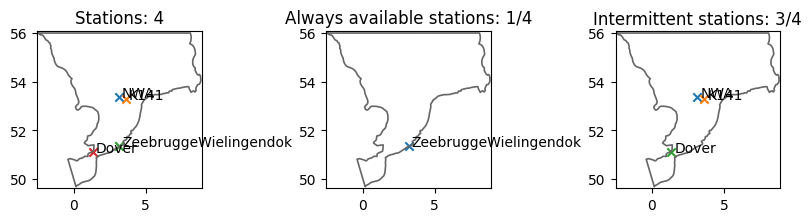

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 4])
Always-available measurements shape: torch.Size([35039, 1])


In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

# read datasets
ds = dfs.read()
dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

del dfs

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
hf = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]
alllist = [s for s in alllist if s.name in hf]

stations = []
available_stations = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        available_stations.append(alllist[i])
    else:
        intermittent.append(alllist[i])

# extract water level measurements for all stations
measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

fig, axs = plt.subplots(1,3, figsize = (8,3))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(available_stations, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(available_stations)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")
plt.tight_layout()
plt.show()

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in available_stations]
measurements_av = measurements[:, av_indices]

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)
print("Always-available measurements shape:", measurements_av.shape)

# free memory
del dsH, dsU, dsV, ds

In [4]:
# Assuming 30 days per month, 24 hours per day, and measurements every 30 minutes (2 per hour)
lenmonths = (30 * 24 * 2)  
nmonths = H.shape[0] // lenmonths 
ntime_keeped = nmonths * lenmonths 
print(f"Time keeprd: {ntime_keeped}/{H.shape[0]} total steps ({nmonths} months) -> coverage: {100*ntime_keeped/H.shape[0]:.1f}% \n")

# reshape the arrays to (nmonths, lenmonths, nfeatures) for training
H = H[:ntime_keeped].reshape(nmonths, lenmonths, -1)
U = U[:ntime_keeped].reshape(nmonths, lenmonths, -1)
V = V[:ntime_keeped].reshape(nmonths, lenmonths, -1)
measurements = measurements[:ntime_keeped].reshape(nmonths, lenmonths, -1)
measurements_av = measurements_av[:ntime_keeped].reshape(nmonths, lenmonths, -1)    

print("Reshaped H shape:", H.shape)
print("Reshaped U shape:", U.shape)
print("Reshaped V shape:", V.shape)
print("Reshaped measurements shape:", measurements.shape)
print("Reshaped measurements shape:", measurements_av.shape)

#permute the months 
np.random.seed(42)  # For reproducibility
permuted_indices = np.random.permutation(nmonths)
H = H[permuted_indices]
U = U[permuted_indices]
V = V[permuted_indices]
measurements = measurements[permuted_indices]
measurements_av = measurements_av[permuted_indices]

print("\npermutation indices:", permuted_indices)

Time keeprd: 34560/35039 total steps (24 months) -> coverage: 98.6% 

Reshaped H shape: torch.Size([24, 1440, 8532])
Reshaped U shape: torch.Size([24, 1440, 8532])
Reshaped V shape: torch.Size([24, 1440, 8532])
Reshaped measurements shape: torch.Size([24, 1440, 4])
Reshaped measurements shape: torch.Size([24, 1440, 1])

permutation indices: [ 8 16  0 18 11  9 13  1 21  5  2 12 15  3  4 22 17 20 23  7 10 14 19  6]


In [5]:
ERRORS = []

# ROMDataManager
LAGS = 24

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 3               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64,96]     # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## Normal training

In [6]:
import json

# 1. open 1-reconstruction_metrics.json
with open("1-reconstruction_metrics.json") as f:
    metrics = json.load(f)

# 2. best model = lowest NMAE on "Unify all" (test split)
SPLIT = "test"
best = min(metrics, key=lambda m: metrics[m][SPLIT]["Unify all"]["nmae"])
print(f"Best model: {best} (NMAE unify all, {SPLIT}) = {metrics[best][SPLIT]['Unify all']['nmae']}")

# 3. write it to 2-reconstruction_metrics.json as "last_step_{model}"
with open("2-reconstruction_metrics.json", "w") as f:
    json.dump({f"last_step_{best}": metrics[best]}, f, indent=2)

Best model: T3E (NMAE unify all, test) = 0.008603314570095999


## Lagged Training (T3E)

In [7]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, pad_output=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1] 
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 26393

Data shapes after preparation:
Train:	 torch.Size([27360, 24, 4]) -> torch.Size([27360, 24, 120])
Val:	 torch.Size([2880, 24, 4]) -> torch.Size([2880, 24, 120])
Test:	 torch.Size([4320, 24, 4]) -> torch.Size([4320, 24, 120])

Input shape for the model: 4
Output shape for the model: 120


In [8]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels = True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, decoder_3D = True
)
mshred = mSHRED(args=model_args).to(device)

W_FACTOR = 0.8
W_KEEPED_TIMESTEPS = 16

# check if the model is already trained and load the weights if available
model_path = Path("models_saved/T3E_LAGGED.pth")
if model_path.exists():
    print(f"Loading pre-trained model from {model_path}")
    mshred.load_state_dict(torch.load(model_path, map_location=device))

else:

    # Use cosine annealing LR schedule
    train_errors, valid_errors = lagged_fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, w_factor=W_FACTOR, w_keeped_steps=W_KEEPED_TIMESTEPS, masking_type=MASKING_TYPE,
    )

    # Save the trained model
    model_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(mshred.state_dict(), model_path)

#eval_all_lagged(manager, mshred, train_dataset, val_dataset, test_dataset, H, U, V, model_name="multi_step_T3E")

#del model_args, model_path, mshred

Loading pre-trained model from models_saved/T3E_LAGGED.pth
